<a href="https://colab.research.google.com/github/wawaelenti/Machine-Learning/blob/main/Agglomerative_Cosine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Agglomerative — Cosine

Average linkage untuk semua metrik; k sama dengan KMeans. Implementasi scipy linkage/cut_tree divalidasi terhadap sklearn AgglomerativeClustering.

Hasil pada PBL lengkap dan dua dataset kontrol. Kode fit pada experiment.py; jalankan ulang dari notebook utama atau terminal.

In [ ]:
from pathlib import Path
import sys, json, subprocess
import pandas as pd
from IPython.display import display, Image, Markdown, Code
ROOT = Path.cwd() if (Path.cwd() / 'experiment.py').exists() else Path.cwd() / 'JS04_v2'
sys.path.insert(0, str(ROOT))
import experiment as pipeline
import inspect
OUT = ROOT / 'hasil'
def show_table(name, algorithm=None, metric=None):
    data = pd.read_csv(OUT / name / 'hasil_semua.csv')
    if algorithm: data = data[data.Algoritma == algorithm]
    if metric: data = data[data.Metrik == metric]
    display(data.round(4))
def show_image(name, filename):
    display(Image(filename=str(OUT / name / filename), width=1000))


## Kode algoritma

In [ ]:
display(Code(inspect.getsource(pipeline.fit_hierarchical), language='python'))

def fit_hierarchical(X, k, metric):
    condensed = pdist(X, metric='cityblock' if metric == 'manhattan' else metric)
    Z = linkage(condensed, method='average')
    labels = cut_tree(Z, n_clusters=[k]).ravel()
    return labels, Z, condensed

## PBL — fitur situs legitimate/phishing

In [ ]:
show_table('pbl', 'Agglomerative', 'cosine')
parameters = pd.read_csv(OUT / 'pbl' / 'parameter_final.csv')
display(parameters[(parameters.Algoritma == 'Agglomerative') & (parameters.Metrik == 'cosine')])

,Dataset,Algoritma,Metrik,k,% noise,Silhouette,DBI,ARI,NMI,ARI non-noise,NMI non-noise,n evaluasi internal,status internal,Waktu (ms),Std waktu (ms),Cophenetic correlation,Cluster terkecil,Cluster terbesar
8,pbl,Agglomerative,cosine,2,0.0,0.0912,4.4173,0.2512,0.1916,0.2512,0.1916,11430,valid,10573.7438,97.6805,0.4979,5273.0,6157.0


,Dataset,Algoritma,Metrik,random_state,k,n_init,max_iter,implementasi,eps,min_samples,algorithm,linkage,n_clusters,cut_height,tie_at_cut,min_cluster_size
10,pbl,Agglomerative,cosine,deterministik,NaN,NaN,NaN,scipy linkage + cut_tree,NaN,NaN,NaN,average,2.0,1.03146,False,NaN


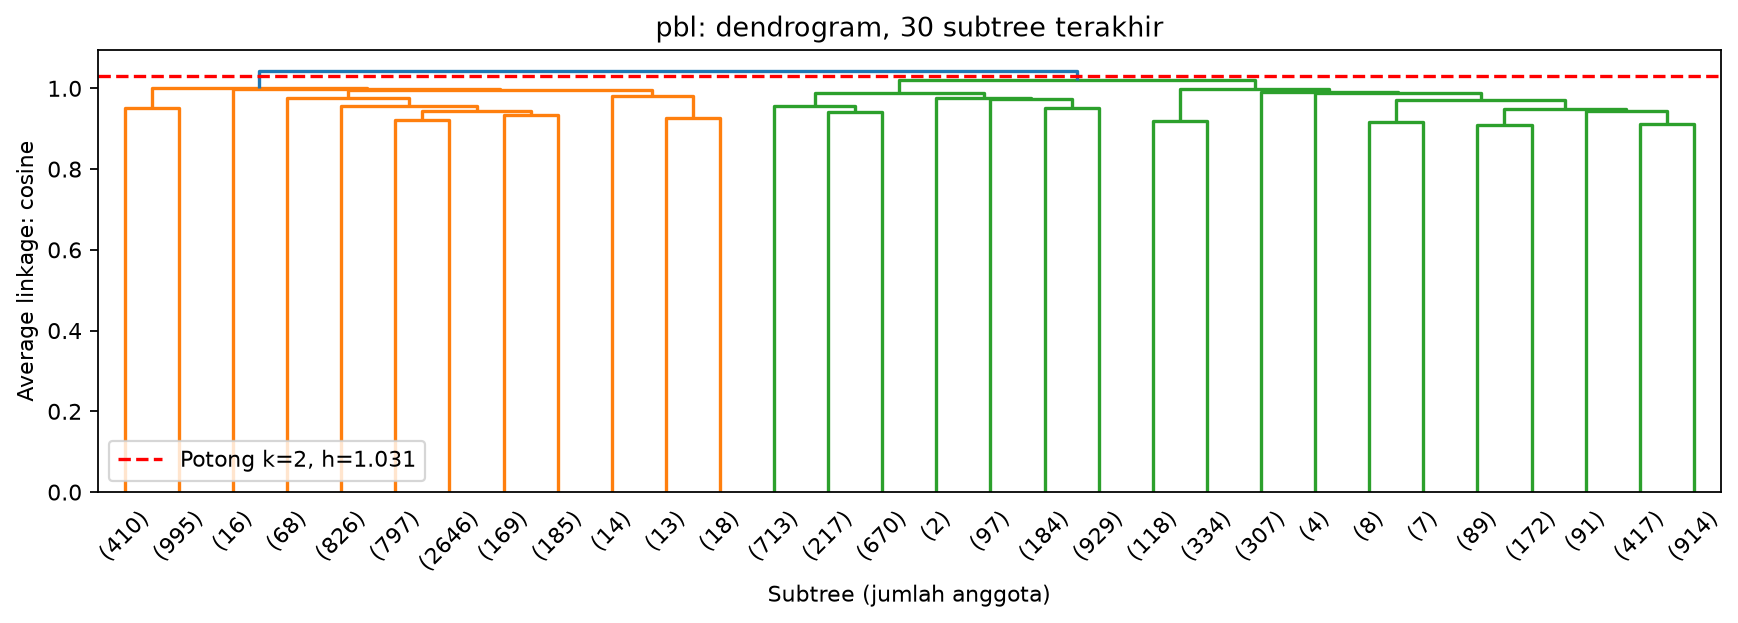

In [ ]:
show_image('pbl', 'dendrogram_cosine.png')

,Jumlah data
Agglomerative_cosine,
0,5273
1,6157


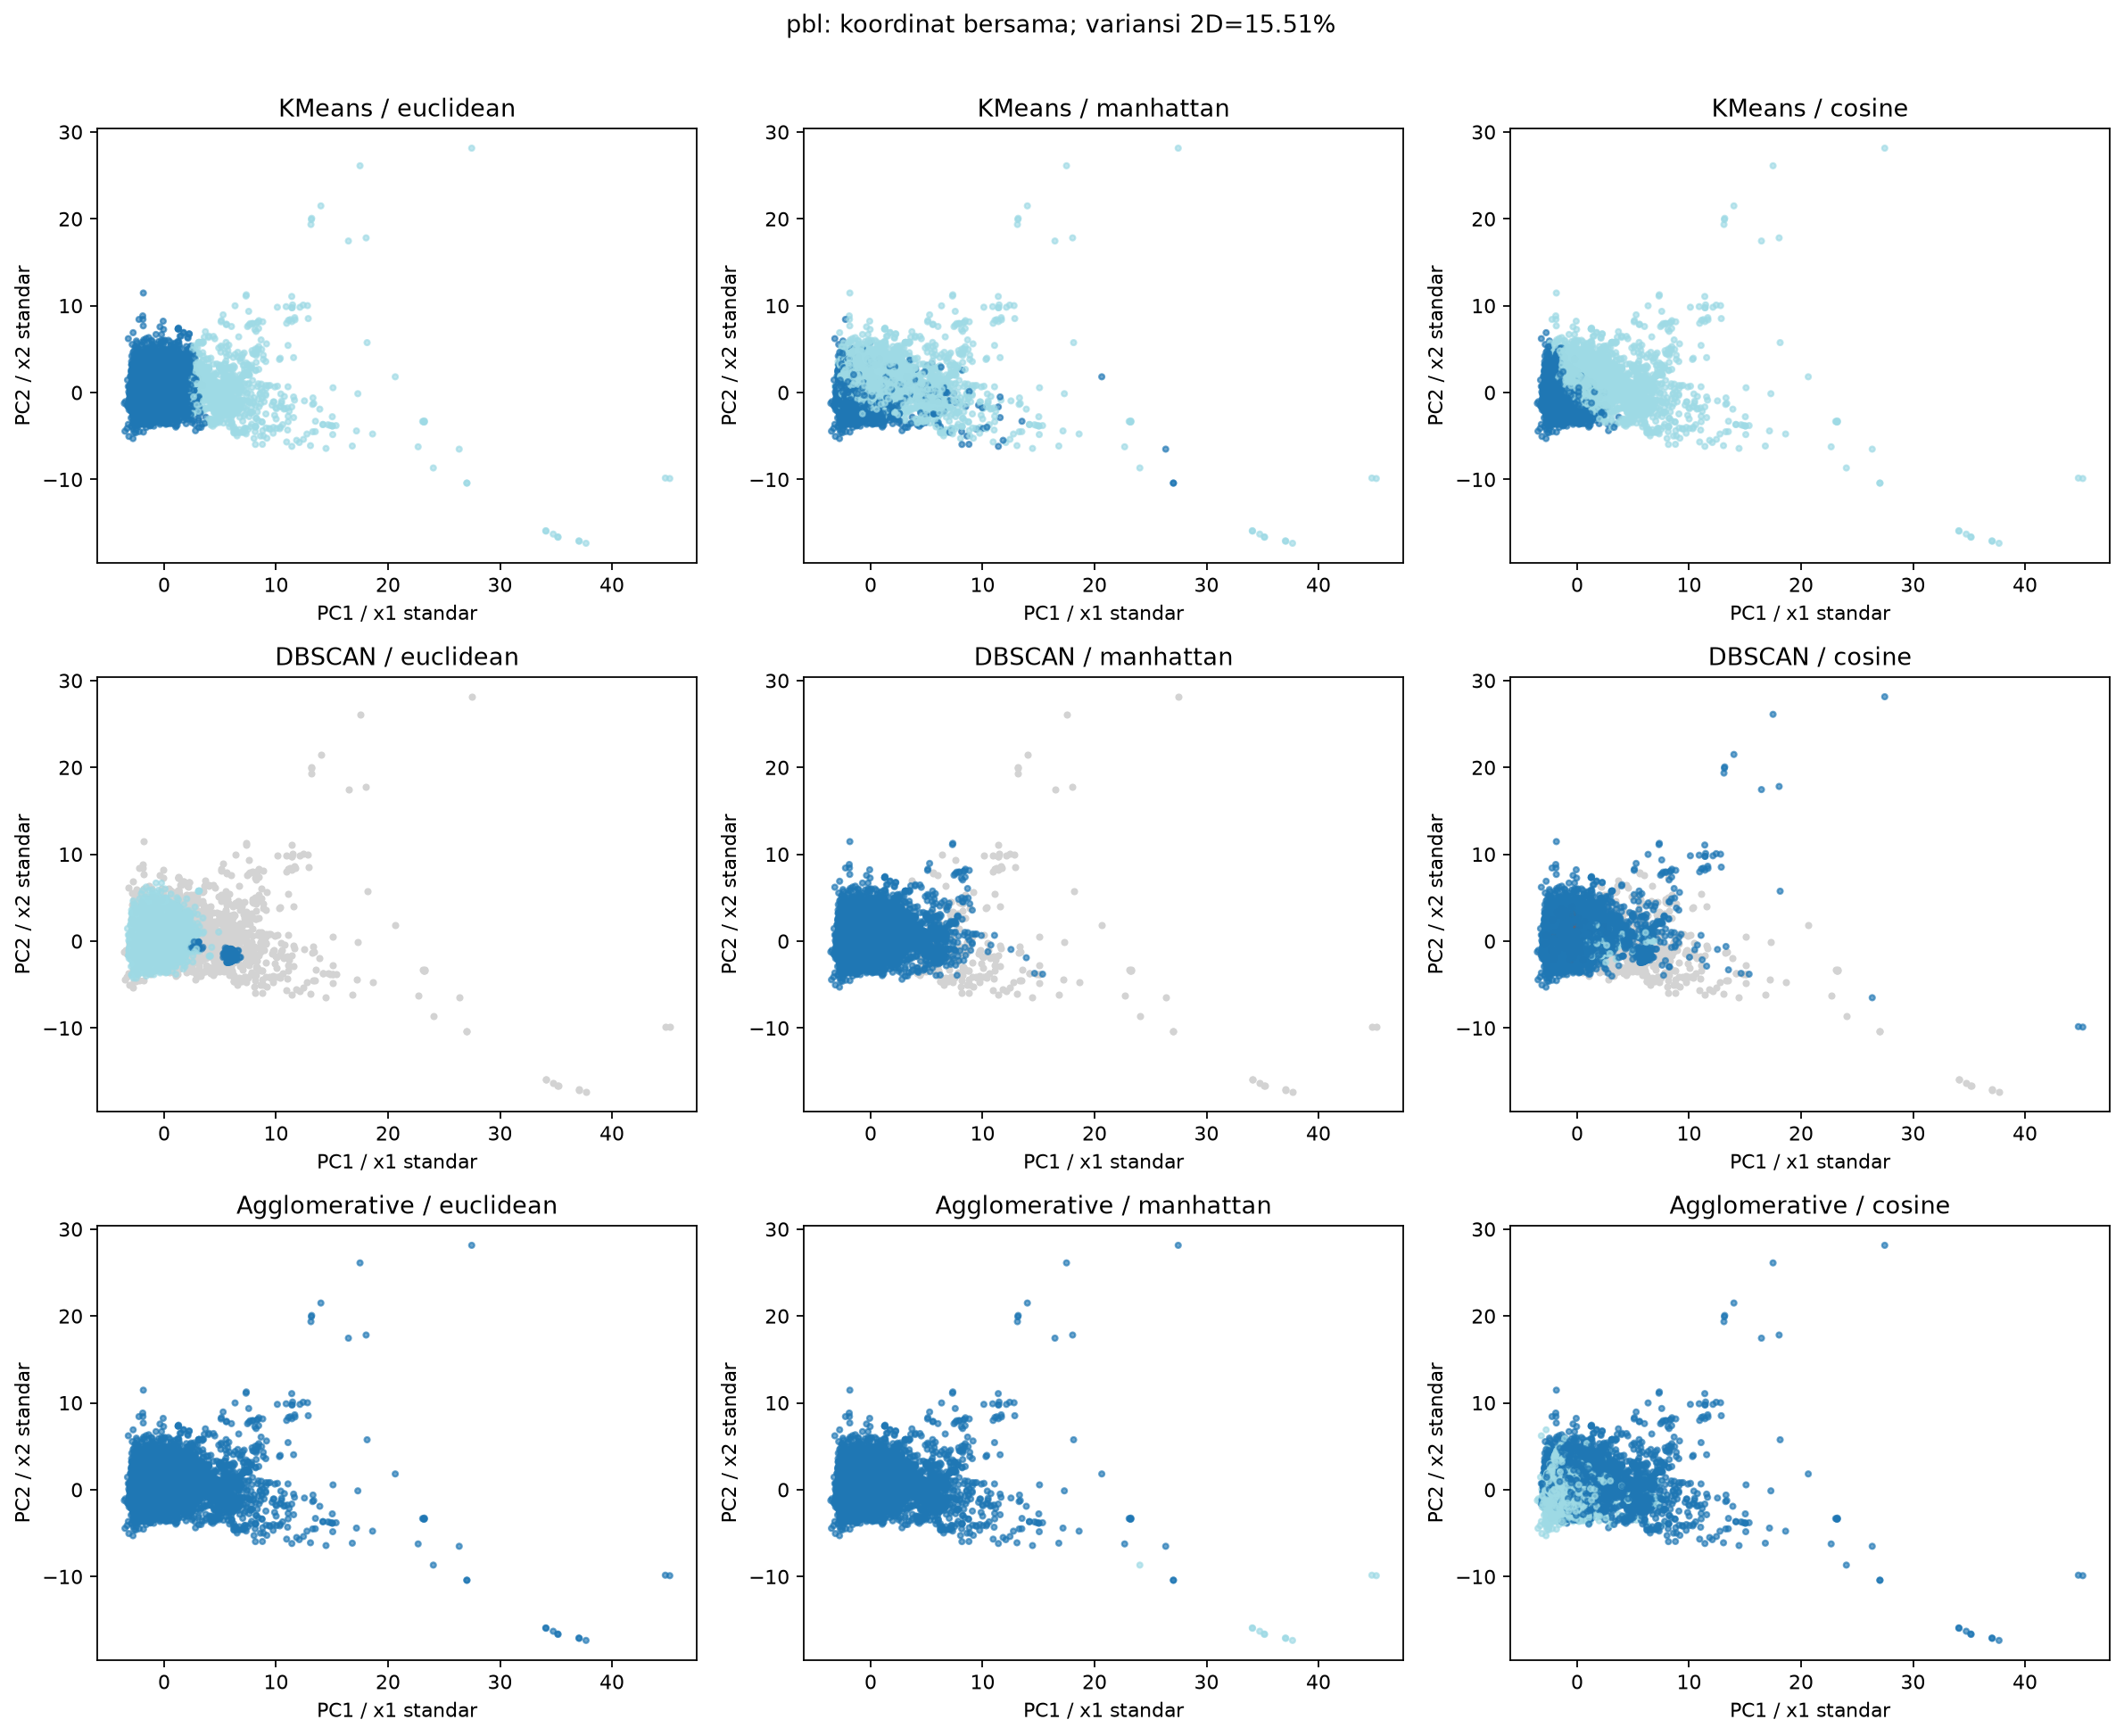

In [ ]:
labels = pd.read_csv(OUT / 'pbl' / 'label_cluster.csv')['Agglomerative_cosine']
display(labels.value_counts().sort_index().rename('Jumlah data').to_frame())
show_image('pbl', 'grid_3x3.png')

## Kontrol make_blobs

In [ ]:
show_table('blobs', 'Agglomerative', 'cosine')
parameters = pd.read_csv(OUT / 'blobs' / 'parameter_final.csv')
display(parameters[(parameters.Algoritma == 'Agglomerative') & (parameters.Metrik == 'cosine')])

,Dataset,Algoritma,Metrik,k,% noise,Silhouette,DBI,ARI,NMI,ARI non-noise,NMI non-noise,n evaluasi internal,status internal,Waktu (ms),Std waktu (ms),Cophenetic correlation,Cluster terkecil,Cluster terbesar
8,blobs,Agglomerative,cosine,4,0.0,0.9699,0.1891,1.0,1.0,1.0,1.0,500,valid,39.7551,0.7045,0.8885,125.0,125.0


,Dataset,Algoritma,Metrik,random_state,k,n_init,max_iter,implementasi,eps,min_samples,algorithm,linkage,n_clusters,cut_height,tie_at_cut,min_cluster_size
10,blobs,Agglomerative,cosine,deterministik,NaN,NaN,NaN,scipy linkage + cut_tree,NaN,NaN,NaN,average,4.0,0.367106,False,NaN


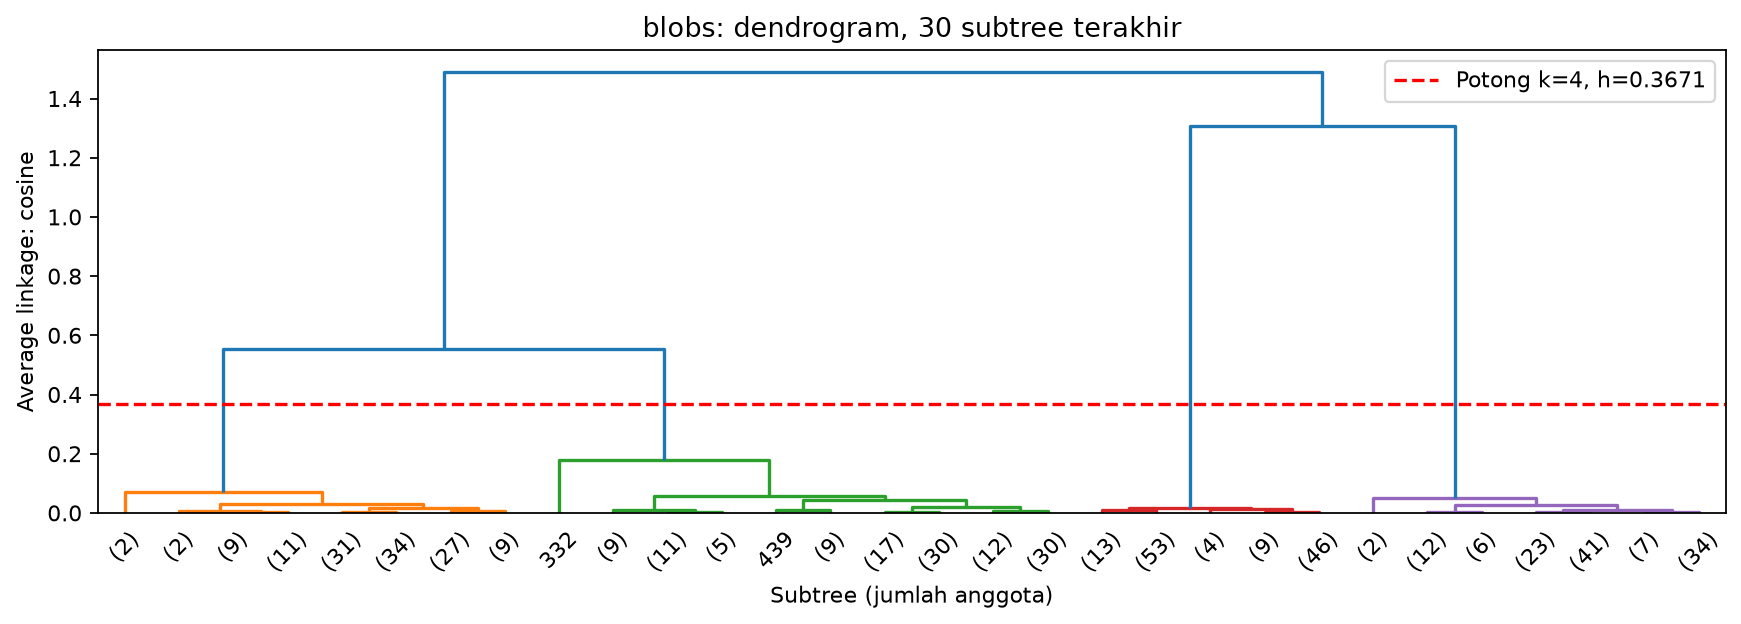

In [ ]:
show_image('blobs', 'dendrogram_cosine.png')

,Jumlah data
Agglomerative_cosine,
0,125
1,125
2,125
3,125


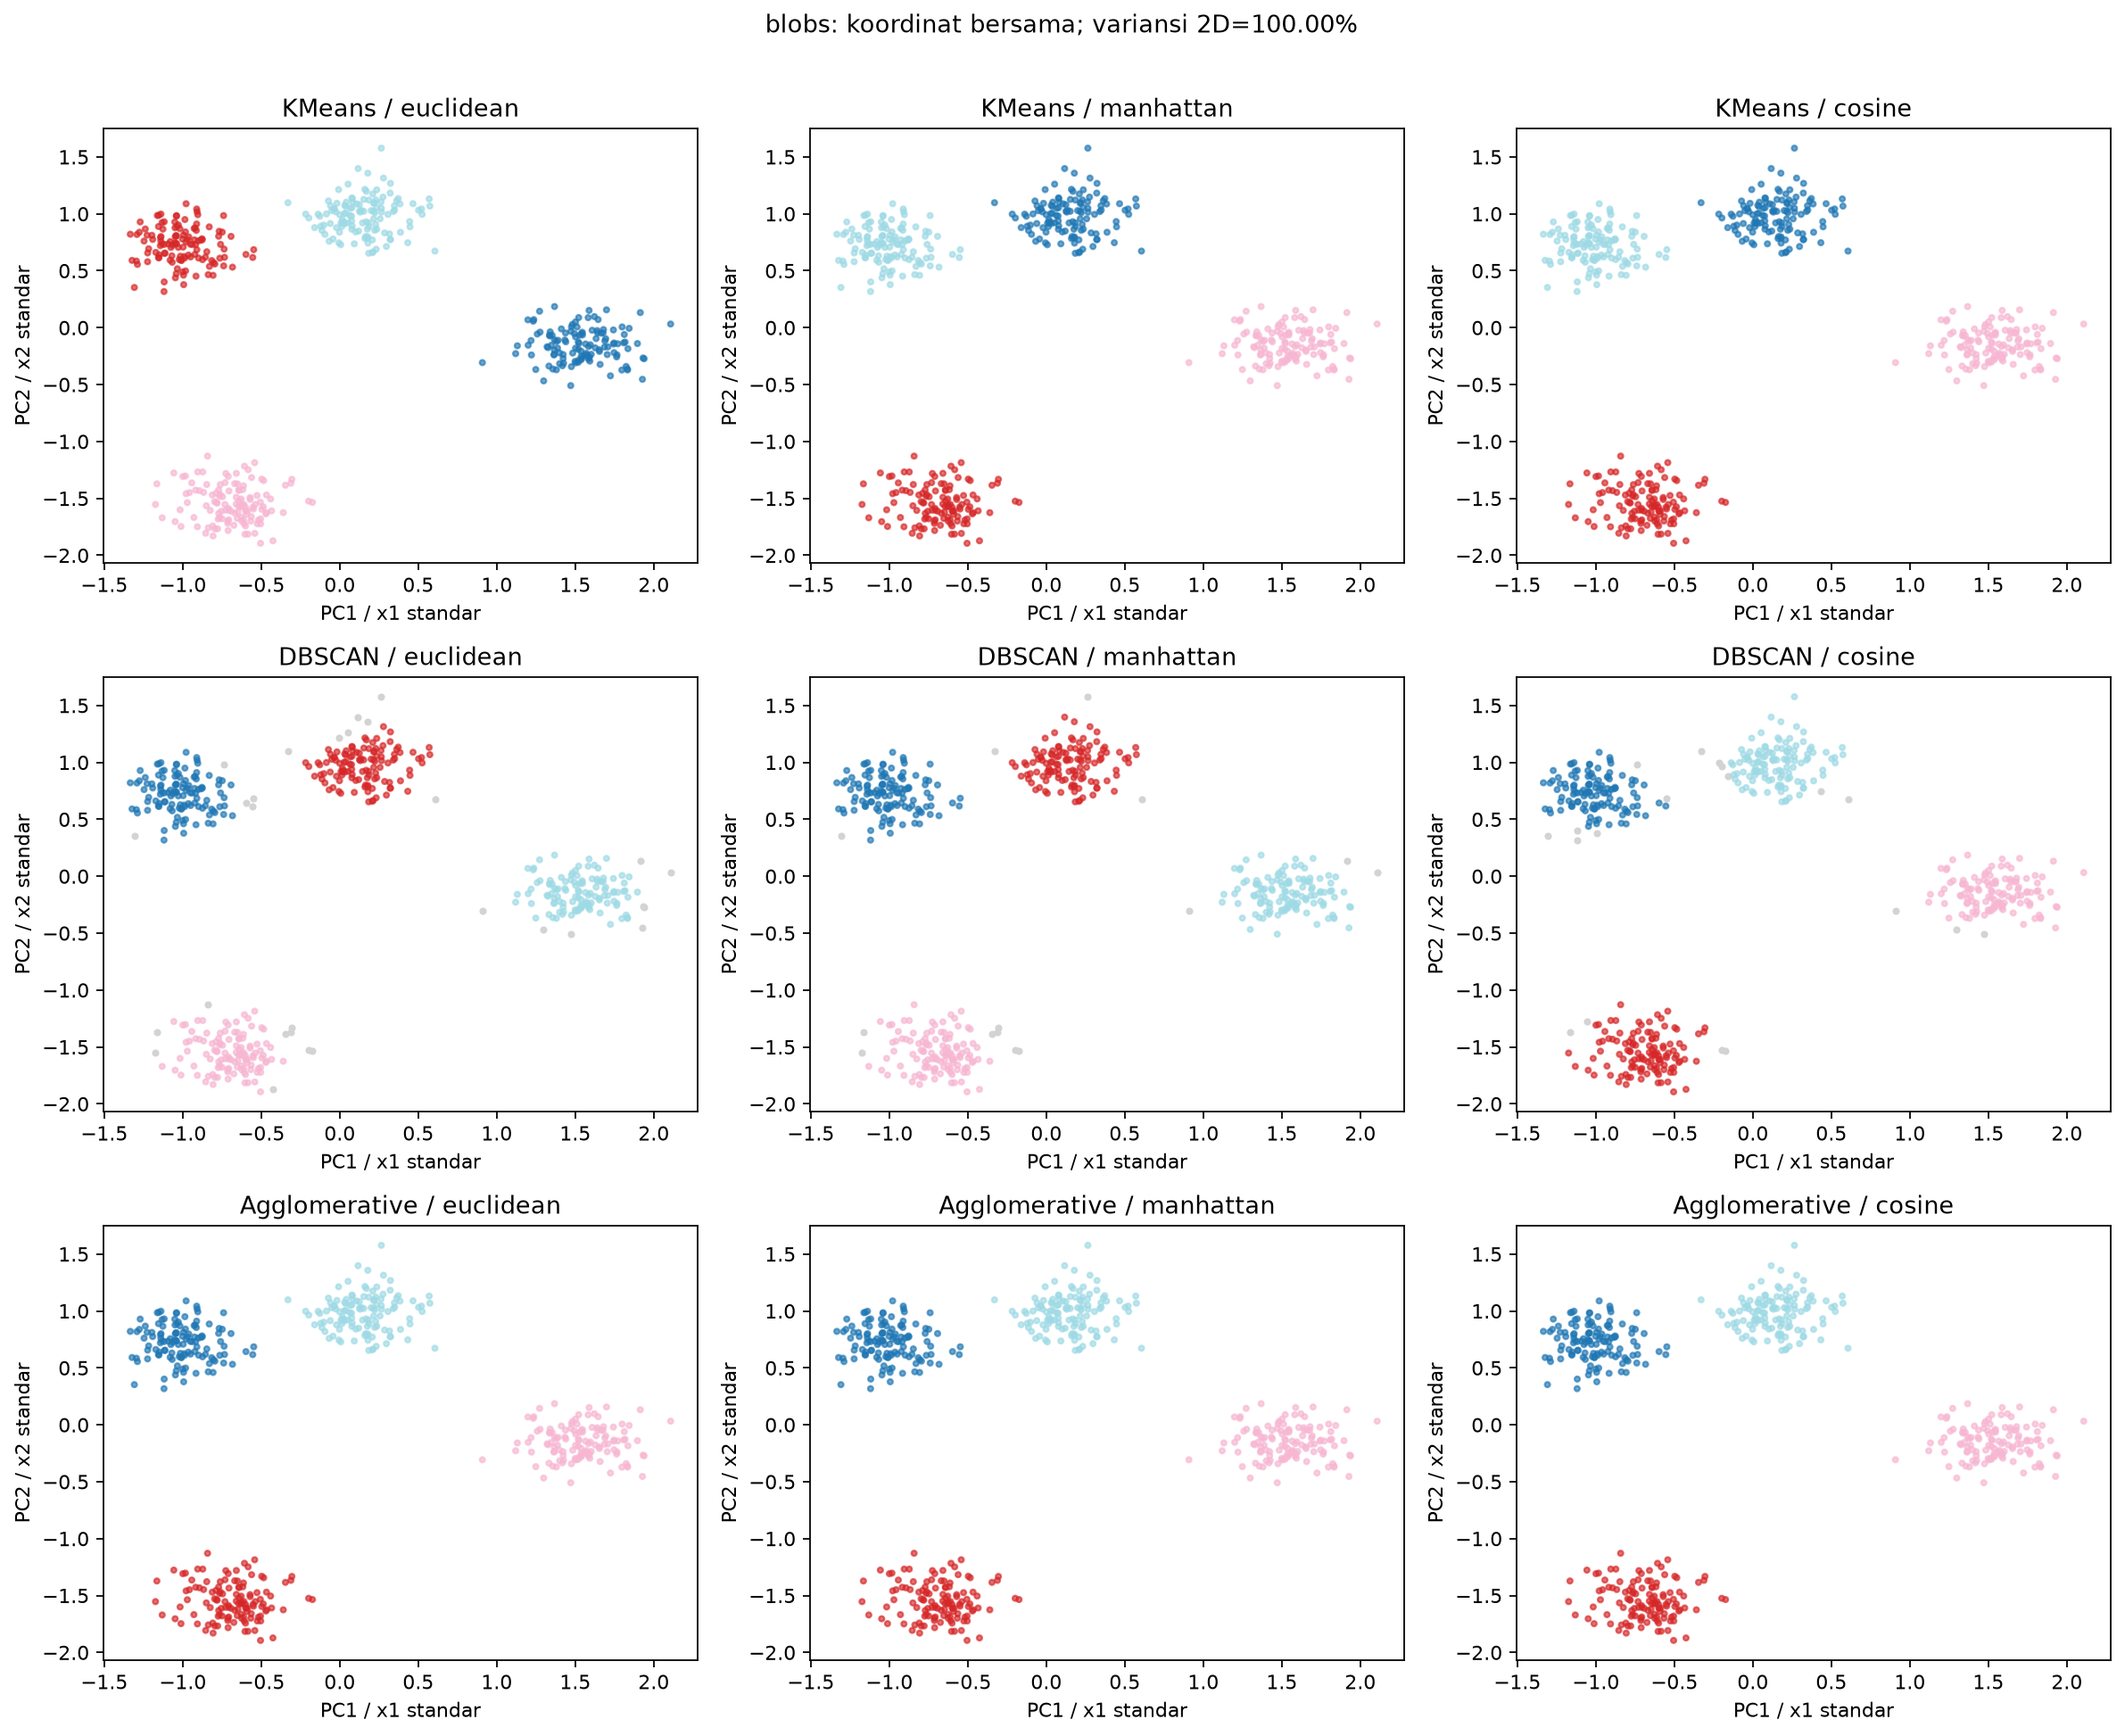

In [ ]:
labels = pd.read_csv(OUT / 'blobs' / 'label_cluster.csv')['Agglomerative_cosine']
display(labels.value_counts().sort_index().rename('Jumlah data').to_frame())
show_image('blobs', 'grid_3x3.png')

## Kontrol make_moons

In [ ]:
show_table('moons', 'Agglomerative', 'cosine')
parameters = pd.read_csv(OUT / 'moons' / 'parameter_final.csv')
display(parameters[(parameters.Algoritma == 'Agglomerative') & (parameters.Metrik == 'cosine')])

,Dataset,Algoritma,Metrik,k,% noise,Silhouette,DBI,ARI,NMI,ARI non-noise,NMI non-noise,n evaluasi internal,status internal,Waktu (ms),Std waktu (ms),Cophenetic correlation,Cluster terkecil,Cluster terbesar
8,moons,Agglomerative,cosine,2,0.0,0.707,0.7815,0.4723,0.3762,0.4723,0.3762,500,valid,40.0991,1.9276,0.8328,242.0,258.0


,Dataset,Algoritma,Metrik,random_state,k,n_init,max_iter,implementasi,eps,min_samples,algorithm,linkage,n_clusters,cut_height,tie_at_cut,min_cluster_size
10,moons,Agglomerative,cosine,deterministik,NaN,NaN,NaN,scipy linkage + cut_tree,NaN,NaN,NaN,average,2.0,1.166257,False,NaN


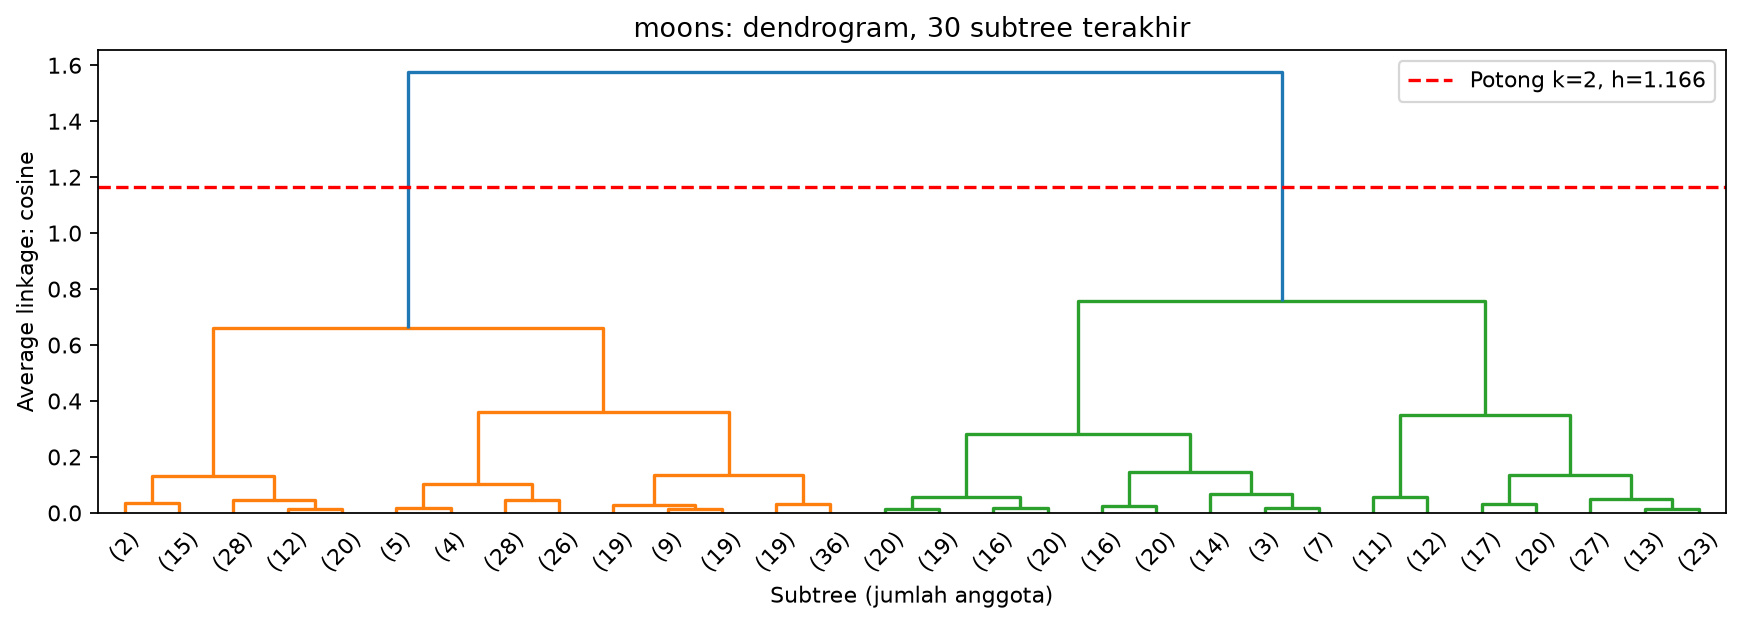

In [ ]:
show_image('moons', 'dendrogram_cosine.png')

,Jumlah data
Agglomerative_cosine,
0,242
1,258


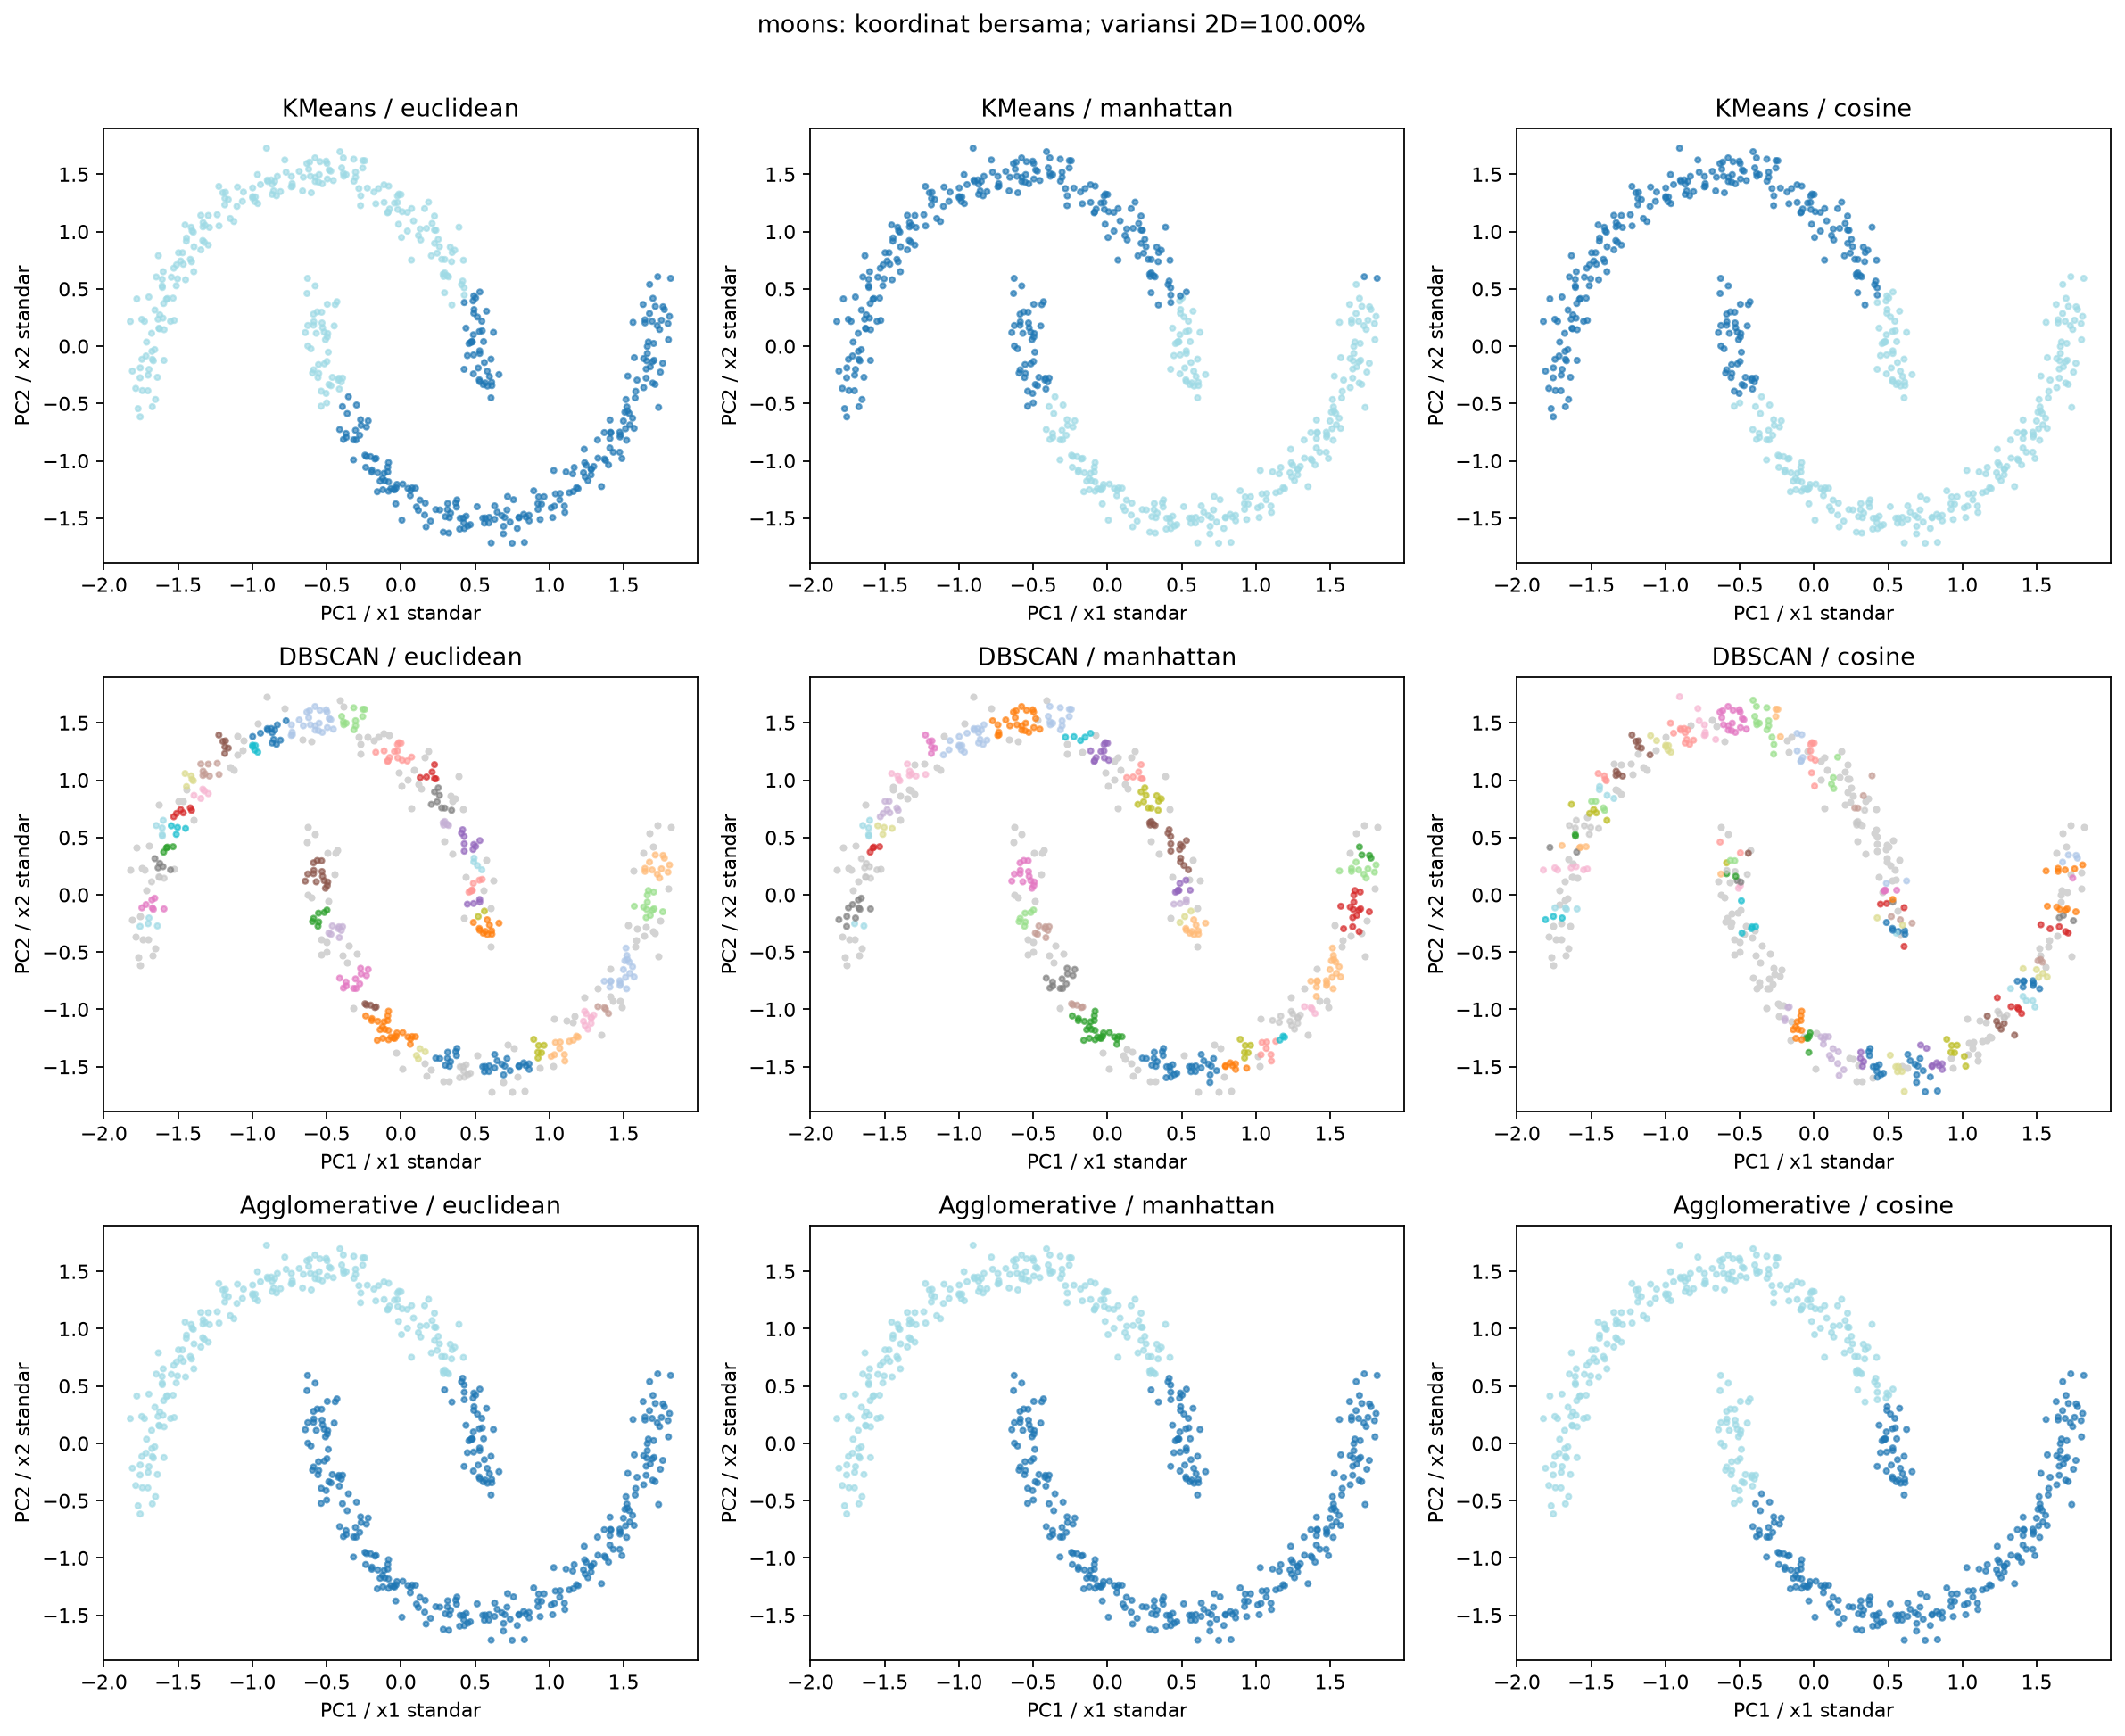

In [ ]:
labels = pd.read_csv(OUT / 'moons' / 'label_cluster.csv')['Agglomerative_cosine']
display(labels.value_counts().sort_index().rename('Jumlah data').to_frame())
show_image('moons', 'grid_3x3.png')